<a href="https://colab.research.google.com/github/Art207141/Labs_sbor_analyz/blob/main/lab04/%D0%9B%D0%B0%D0%B1_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
import os
import pandas as pd
from scipy import stats

drive.mount('/content/drive')

folder_path = '/content/drive/MyDrive/ДАТАСЕТЫ/'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Гипотезы (Пренатальная диагностика)

Родилось мальчиков (1): 577, девочек (0): 473

ЧИСЛОВЫЕ ХАРАКТЕРИСТИКИ ПОКАЗАТЕЛЕЙ:
                       min          max       размах         mean      медиана
vozrast          16.000000    45.000000    29.000000    28.681905    28.000000
gr-dni           70.000000   108.000000    38.000000    88.764762    88.000000
ctr              45.000000    85.000000    40.000000    64.125714    64.000000
nt                0.300000     2.800000     2.500000     1.337333     1.300000
rost             45.000000    60.000000    15.000000    51.698095    52.000000
ves            2410.000000  5040.000000  2630.000000  3435.779048  3430.000000
pol(1-м, 0-д)     0.000000     1.000000     1.000000     0.549524     1.000000
ИМТ               8.686365    18.117451     9.431086    12.829898    12.801384


ПРОВЕРКА НА НОРМАЛЬНОСТЬ (Тест Шапиро-Уилка, альфа=0.05):
При нормальном распределении асимметрия и эксцесс должны равняться 0.
---------------------------------------------------------------------------

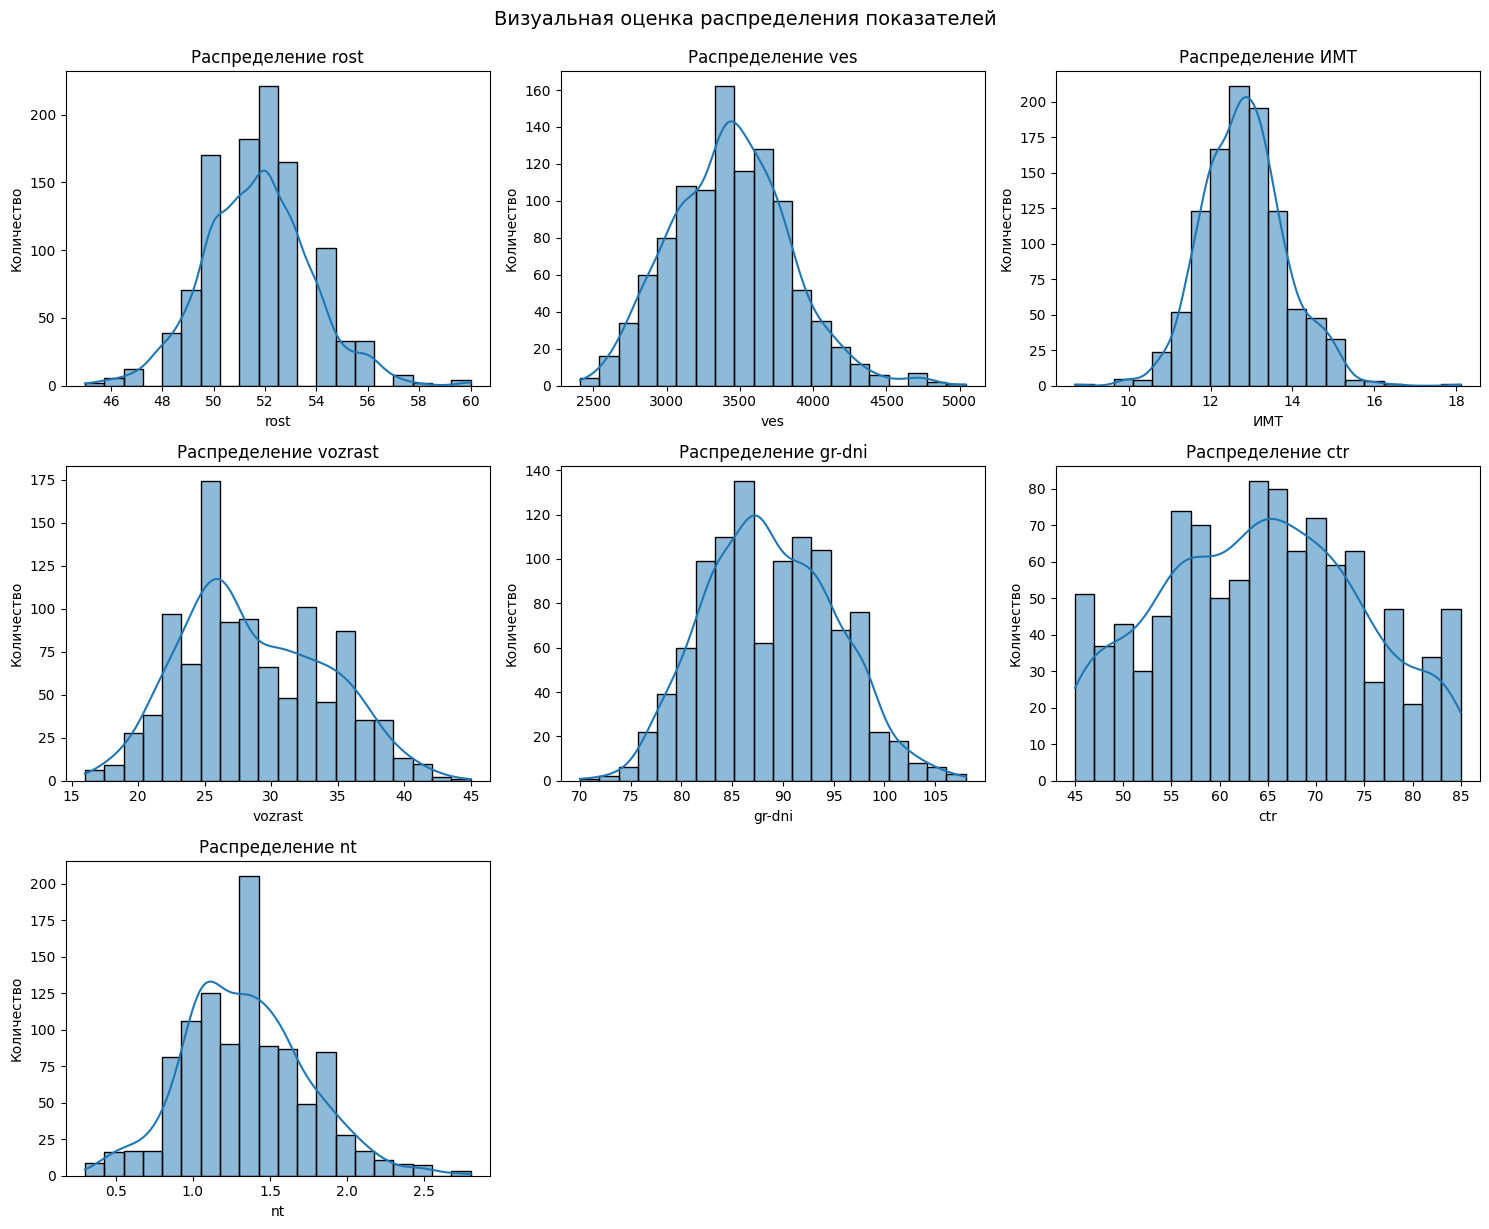



ИССЛЕДОВАНИЕ ГЕНДЕРНЫХ РАЗЛИЧИЙ (Т-тест Стьюдента/Уэлча):

Параметр [ROST]:
  Среднее значение у мальчиков: 52.00
  Среднее значение у девочек:  51.33
  Параметры Т-теста: t-statistic = 5.2729, p-value = 0.00000
  Вывод: Статистически значимые гендерные различия ЕСТЬ

Параметр [VES]:
  Среднее значение у мальчиков: 3497.46
  Среднее значение у девочек:  3360.54
  Параметры Т-теста: t-statistic = 5.6075, p-value = 0.00000
  Вывод: Статистически значимые гендерные различия ЕСТЬ

Параметр [ИМТ]:
  Среднее значение у мальчиков: 12.91
  Среднее значение у девочек:  12.74
  Параметры Т-теста: t-statistic = 2.7048, p-value = 0.00695
  Вывод: Статистически значимые гендерные различия ЕСТЬ


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

file_prenatal = os.path.join(folder_path, 'Пренатальная диагностика.xlsx')
df_pre = pd.read_excel(file_prenatal)

# Подсчет количества мальчиков и девочек
counts = df_pre['pol(1-м, 0-д)'].value_counts()
print(f"Родилось мальчиков (1): {counts.get(1, 0)}, девочек (0): {counts.get(0, 0)}\n")

# Добавление столбца ИМТ
# ИМТ: Вес(кг) / Рост(м)^2. В датасете вес в граммах, рост в см.
df_pre['ИМТ'] = (df_pre['ves'] / 1000) / ((df_pre['rost'] / 100) ** 2)

# Нахождение числовых характеристик
print("ЧИСЛОВЫЕ ХАРАКТЕРИСТИКИ ПОКАЗАТЕЛЕЙ:")
desc = df_pre.describe().T
desc['размах'] = desc['max'] - desc['min']
# Переименуем 50% в медиану для наглядности
desc = desc.rename(columns={'50%': 'медиана'})
print(desc[['min', 'max', 'размах', 'mean', 'медиана']])
print("\n" + "="*80 + "\n")

# Проверка показателей на нормальность
print("ПРОВЕРКА НА НОРМАЛЬНОСТЬ (Тест Шапиро-Уилка, альфа=0.05):")
print("При нормальном распределении асимметрия и эксцесс должны равняться 0.")
print("-" * 80)

metrics_to_test = ['rost', 'ves', 'ИМТ', 'vozrast', 'gr-dni', 'ctr', 'nt']
for col in metrics_to_test:
    if col in df_pre.columns:
        skew = df_pre[col].skew()
        kurt = df_pre[col].kurt()
        stat, p_normal = stats.shapiro(df_pre[col].dropna())

        is_normal = "Распределение Гаусса (Нормальное)" if p_normal > 0.05 else "Ненормальное распределение"
        print(f"Показатель '{col}':")
        print(f"  -> Асимметрия: {skew:.3f}, Эксцесс: {kurt:.3f}")
        print(f"  -> Критерий нормальности p-value: {p_normal:.5f} ({is_normal})\n")

# Визуальная оценка (построение гистограмм с KDE через seaborn)
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(metrics_to_test):
    if col in df_pre.columns:
        sns.histplot(df_pre[col].dropna(), bins=20, kde=True, ax=axes[i])
        axes[i].set_title(f"Распределение {col}")
        axes[i].set_ylabel("Количество")

# Скрываем неиспользуемые графики (так как показателей 7, а ячеек в сетке 9)
for j in range(len(metrics_to_test), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.suptitle("Визуальная оценка распределения показателей", fontsize=14, y=1.02)
plt.show()

print("\n" + "="*80 + "\n")

# Исследование гендерных различий антропометрических параметров (Рост, Вес, ИМТ)
print("ИССЛЕДОВАНИЕ ГЕНДЕРНЫХ РАЗЛИЧИЙ (Т-тест Стьюдента/Уэлча):")
for col in ['rost', 'ves', 'ИМТ']:
    males = df_pre[df_pre['pol(1-м, 0-д)'] == 1][col].dropna()
    females = df_pre[df_pre['pol(1-м, 0-д)'] == 0][col].dropna()

    # Проверка равенства дисперсий критерием Левена
    _, p_lev = stats.levene(males, females)
    eq_var = p_lev > 0.05

    t_stat, p_val = stats.ttest_ind(males, females, equal_var=eq_var)
    conclusion = "Статистически значимые гендерные различия ЕСТЬ" if p_val < 0.05 else "Гендерных различий НЕ ОБНАРУЖЕНО"

    print(f"\nПараметр [{col.upper()}]:")
    print(f"  Среднее значение у мальчиков: {males.mean():.2f}")
    print(f"  Среднее значение у девочек:  {females.mean():.2f}")
    print(f"  Параметры Т-теста: t-statistic = {t_stat:.4f}, p-value = {p_val:.5f}")
    print(f"  Вывод: {conclusion}")

# Т-тесты (Психология)

In [ ]:
# Загрузка файла
file_psy = os.path.join(folder_path, 'Психологи.xlsx')
df_psy = pd.read_excel(file_psy)

# Удаляем лишние пробелы из текстовых значений, если они есть
for col in df_psy.columns:
    if df_psy[col].dtype == 'object':
        df_psy[col] = df_psy[col].astype(str).str.strip()

# Принудительно берем 2-й столбец как группирующий (Пол)
sex_column = df_psy.columns[1]

# Числовые показатели начинаются с 5-го столбца (индекс 4)
features = df_psy.columns[4:]

print(f"{'Показатель':<25} | {'t-статистика':<12} | {'p-значение':<10} | {'Вывод'}")
print("-" * 75)

p_values = {}

for col in features:
    # Разделение выборки на группы по полу
    males = df_psy[df_psy[sex_column] == 'м'][col].dropna()
    females = df_psy[df_psy[sex_column] == 'ж'][col].dropna()

    if len(males) == 0 or len(females) == 0:
        continue

    # f-тест Левена на равенство дисперсий
    _, p_levene = stats.levene(males, females)
    equal_var = p_levene > 0.05

    # Т-тест Стьюдента или Уэлча
    t_stat, p_val = stats.ttest_ind(males, females, equal_var=equal_var)
    p_values[col] = p_val

    # Вывод
    conclusion = "Различия ЗНАЧИМЫ" if p_val < 0.05 else "Различий нет"
    print(f"{col:<25} | {t_stat:<12.4f} | {p_val:<10.4f} | {conclusion}")

print("\n" + "="*65)
significant = {k: v for k, v in p_values.items() if v < 0.05}

if significant:
    strongest = min(significant, key=significant.get)
    print(f"* Сильнее всего гендерные различия проявились в показателе: '{strongest}' (p-value = {p_values[strongest]:.5f})")
else:
    print("* Статистически значимых различий (при альфа=0.05) не обнаружено ни в одном показателе.")

weakest = max(p_values, key=p_values.get)
print(f"* Слабее всего различия проявились в показателе: '{weakest}' (p-value = {p_values[weakest]:.5f})")

Показатель                | t-статистика | p-значение | Вывод
---------------------------------------------------------------------------
 осведомленность          | -1.4732      | 0.1478     | Различий нет
 скрытые фигуры           | -2.0113      | 0.0504     | Различий нет
 пропущенные слова        | -0.6218      | 0.5373     | Различий нет
 арифметика               | 1.6686       | 0.1023     | Различий нет
 понятливость             | -0.5255      | 0.6019     | Различий нет
 исключение  изображений  | -1.3573      | 0.1816     | Различий нет
 аналогии                 | 0.9194       | 0.3629     | Различий нет
 числовые ряды            | 1.6023       | 0.1163     | Различий нет
 умозаключения            | 0.3022       | 0.7639     | Различий нет
 геометрическое  сложение | 1.3373       | 0.1880     | Различий нет
 заучивание слов          | -1.5355      | 0.1318     | Различий нет
 средний IQ               | -0.1657      | 0.8691     | Различий нет
 экстраверсия- интроверсия | -3.44